# 🟠 Tarefa 4

* Disciplina: Física com Python 1 (2026.2) — CBPF
* Autor: Luiz Guilherme Ataliba dos Reis
* Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

> **Entrega:** colocar no GitHub.

## 🔶 Parte 1

Vá à tabela do slide 36 desta [apresentação](https://docs.google.com/presentation/d/1Cbj5JP3zd2teq8xfyt7Li24cBLYrC5tI2MuddnAfN9w/edit?usp=sharing) e **escolha dois mapas caóticos**. Faça uma simulação para comparar os resultados com as expressões analíticas do expoente de Lyapunov e da densidade invariante.

# 🔵 Teoria
Vasmos considerar o **mapa logístico** e o **mapa de tenda** para esse exemplo. O expoente de lyapunov pode ser calculado pela seguinte expressão:

$$
    \lambda = \lim_{n\to\infty} \frac{1}{n}\sum_{i=0}^{n-1}\ln|f'(x_i)|,
$$
note que a condição do limite, de forma computacional, significa considerarmos um grande número/tempo de simulação (até o parâmetro convergir). Para os mapas escolhidos, com os parâmetros definidos como $r_{\text{logistico}} = 4$ e $r_{\text{tenda}}=2$, esses valores são conhecidos:

$$
\lambda_{\text{logistico}} = \ln 2 \hspace{25mm} \lambda_{\text{tenda}} = \ln 2
$$

Asssim como a densidade invariante também é conhecida:
$$
\rho_{\text{logistico}}(x) = \frac{1}{\pi\sqrt{x(1-x)}} \hspace{25mm} \rho_{\text{tenda}}(x) = 1
$$

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme("notebook")
sns.set_style("darkgrid")

In [14]:
def expoente_lyapunov(orbita, derivada, parametro):
    return np.mean(np.log(np.abs(derivada(orbita, parametro))))

#### 🔹 Mapa Logístico

In [15]:
def mapa_logistico(x, r):
    return r * x * (1 - x)

def derivada_logistica(x, r):
    return np.abs(r * (1 - 2 * x))

def densidade_logistica(x):
    return 1 / (np.pi * np.sqrt(x * (1 - x)))


In [16]:
# Simulação

# Órbita do logístico em r = 4
PASSOS = 200_000
PASSOS_TRANS = 1000
R_LOG = 4.0
X0 = 0.3123 


# Descartando o transiente
for _ in range(PASSOS_TRANS):
    x = mapa_logistico(X0, R_LOG)

orbita_log = np.empty(PASSOS)
for i in range(PASSOS):
    orbita_log[i] = x
    x = mapa_logistico(x, R_LOG)

lamb_log = expoente_lyapunov(orbita_log, derivada_logistica, R_LOG)

print(f"Logístico: λ simulado = {lamb_log:.5f}  |  λ analítico = {np.log(2):.5f}")


Logístico: λ simulado = 0.69314  |  λ analítico = 0.69315


#### 🔹 Mapa de Tenda

In [17]:
def mapa_tenda(x, r):
    return r * np.minimum(x, 1 - x)

# Derivada do tenda: |f'(x)| = r em todo ponto fora a descontinuidade 
def derivada_tenda(x, r):
    return np.full_like(x, r, dtype=float)

def densidade_tenda(x):
    return np.ones_like(x)

In [18]:
# Simulação

PASSOS = 200_000
R_TEN = 2.0
M = 3**16

k = int(0.3123 * M)
orbita_ten = np.empty(PASSOS)
for i in range(PASSOS):
    k = 2 * k if 2 * k < M else 2 * (M - k)
    orbita_ten[i] = k / M

lamb_ten = expoente_lyapunov(orbita_ten, derivada_tenda, R_TEN)

print(f"Tenda:     λ simulado = {lamb_ten:.5f}  |  λ analítico = ln 2 = {np.log(2):.5f}")


Tenda:     λ simulado = 0.69315  |  λ analítico = ln 2 = 0.69315


Resultado do Expoente de Lyapunov por Mapa

In [19]:
pd.DataFrame([
    {"Mapa": "Logístico", "λ Simulado": lamb_log, "λ Teórico": f"{np.log(2):.5f}"},
    {"Mapa": "Tenda", "λ Simulado": lamb_ten, "λ Teórico": f"{np.log(2):.5f}"}
])

,Mapa,λ Simulado,λ Teórico
0,Logístico,0.693143,0.69315
1,Tenda,0.693147,0.69315


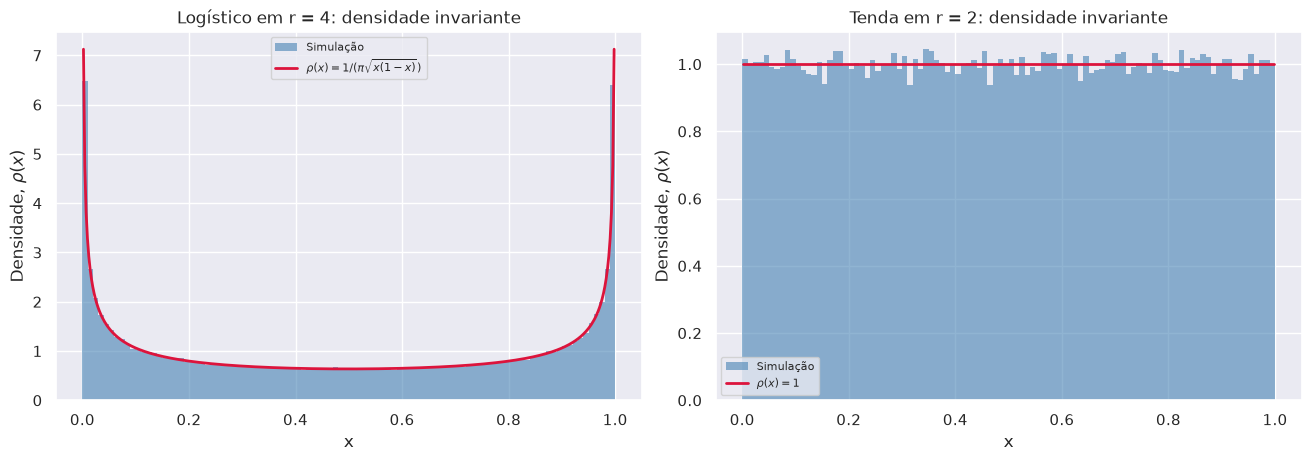

In [20]:
# Plotting

x = np.linspace(0.002, 0.998, 400)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axs[0].hist(orbita_log, bins=100, density=True, color="steelblue", alpha=0.6, edgecolor="none", label="Simulação")
axs[0].plot(x, densidade_logistica(x), color="crimson", lw=2, label=r"$\rho(x) = 1/(\pi\sqrt{x(1-x)})$")
axs[0].set(xlabel="x", ylabel=r"Densidade, $\rho(x)$", title="Logístico em r = 4: densidade invariante")
axs[0].legend(fontsize=8)

axs[1].hist(orbita_ten, bins=100, density=True, color="steelblue", alpha=0.6, edgecolor="none", label="Simulação")
axs[1].plot(x, densidade_tenda(x), color="crimson", lw=2, label=r"$\rho(x) = 1$")
axs[1].set(xlabel="x", ylabel=r"Densidade, $\rho(x)$", title="Tenda em r = 2: densidade invariante")
axs[1].legend(fontsize=8)

### 🔷 Interpretação

#### 🔹 Expoente de Lyapunov
Como já discutido previamente, ambos os mapas tem o mesmo valor do expoente de lyapunov, para o valor escolhido para seus respectivos parâmetros. Dito isso, em ambos os casos os valores simulados se aproximam com erro na ordem de $10^{-5}$ do valor teórico, sendo assim uma ótima estimativa numérica. Além disso, em ambos os casos temos $\lambda>0$ o que indica que os dois mapas apresentam comportamento caótico, como já é conhecido.

#### 🔹 Densidade Invariante
Para o mapa logístico, notase-se que o sistema visita com maior frequência as regiões próximas de 0 e 1, o que está de acordo com a expressão teórica encontrada. No painel direito, podemos observar que a trajetória do mapa de tenda visita as regiões de forma aproximadamente proporcional e igualitária, uma vez que $\rho(x)=1$ não há região favorecida. 

Vale destacar que embora esses sistemas apresentem expoente de lyapunov positivo, suas densidades invariantes são distantas, ou seja, embora possuam a mesma medida referente a divergência das condições inicias, a forma com que eles exploram o espaço é significativamente diferente. Em especial para o mapa de tenda, que mesmo apresentando caos, explora seu espaço de forma aproximadamente igual. 

## 🔶 Parte 2


## 🔶 Mapa logístico

Sobre o artigo abaixo, use a Eq. 5 para obter computacionalmente os resultados equivalentes aos experimentais mostrados nas Figuras 5 e 7.

* Suneel, Madhekar. *Electronic circuit realization of the logistic map*. Sadhana (2006). [Link](https://www.ias.ac.in/public/Volumes/sadh/031/01/0069-0078.pdf)

In [21]:
# Eq. (5) de Suneel
def mapa_logistico_circuito(X, beta):
    return beta * X * (10 - X) / 25


def bifurcacao(mapa, parametros, x0, transiente=1_000, amostras=300):
    x = np.full(parametros.size, x0)
    for _ in range(transiente):
        x = mapa(x, parametros)

    valores = np.empty((parametros.size, amostras))
    for i in range(amostras):
        x = mapa(x, parametros)
        valores[:, i] = x

    return np.repeat(parametros, amostras), valores.ravel()


In [22]:
# beta = 2,5lambda, então beta de 0 a 10 cobre lambda de 0 a 4
BETAS = np.linspace(0.02, 10, 2_000)

betas_sim, X_sim = bifurcacao(mapa_logistico_circuito, BETAS, x0=3.7)

# Região ampliada da Fig. 7: depois da primeira duplicação de período, que ocorre em beta = 7,5
ampliada = betas_sim >= 7.5

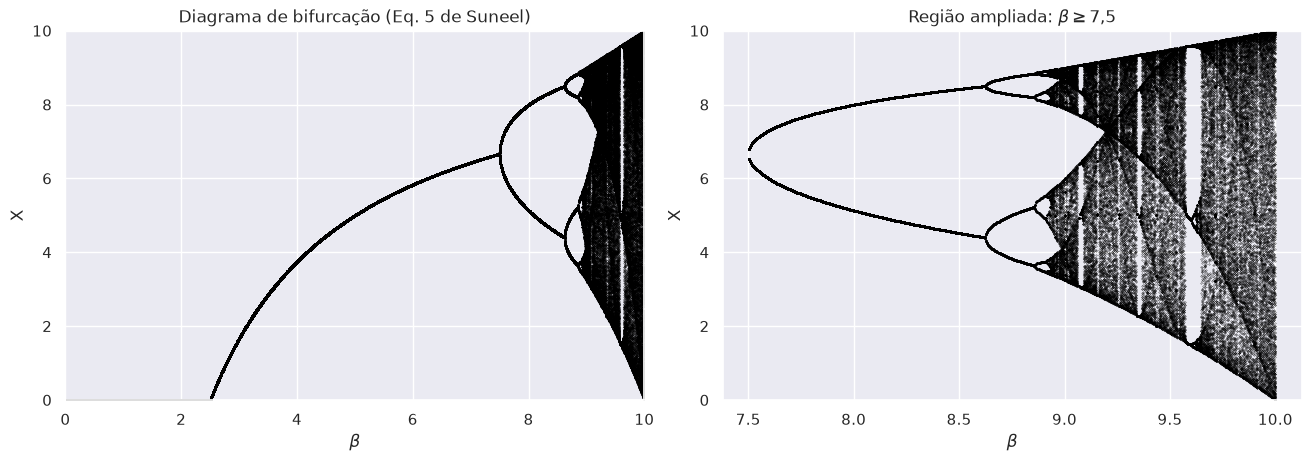

In [23]:
# Plotting

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axs[0].scatter(betas_sim, X_sim, s=0.05, color="black")
axs[0].set(
    xlabel=r"$\beta$",
    ylabel="X",
    title="Diagrama de bifurcação (Eq. 5 de Suneel)",
    xlim=(0, 10),
    ylim=(0, 10),
)

axs[1].scatter(betas_sim[ampliada], X_sim[ampliada], s=0.05, color="black")
axs[1].set(
    xlabel=r"$\beta$",
    ylabel="X",
    title=r"Região ampliada: $\beta \geq 7{,}5$",
    ylim=(0, 10),
)
plt.show()


### 🔷 Interpretação

Da teoria, sabe-se que os dois primeiros pontos de bifurcação para o mapa logístico estão localizados em:
$$
\beta_1 = 2.5 \hspace{25mm} \beta_2 = 7.5.
$$
Esse resultado é observado nos diagramas acima, veja que para $\beta < 2.5$ o sistema converge sempre apara o mesmo ponto fixo $x^*=0$, em $2.5 < \beta < 7.5$ existe um ramo não nulo, porém estável. Já em $\beta=7.5$ ocorre a primeira bifurcação e a partir desse ponto esse fenômeno se repete, de forma que o número de bifurcações cresce rapidamente. 

Em especial com o zoom do quadro direito, observamos claramento a transição do período 2 para período quatro, e desse para o período 8.

## 🔶 Mapa cossenoidal

Sobre o artigo abaixo, use a Eq. 5 para reproduzir a Figura 4. Compare com o resultado experimental correspondente na Figura 3.

* Ma, Yu-Han, et al. *Experimental system of coupled map lattices*. Frontiers of Physics (2015). [Link](https://www.researchgate.net/profile/Yu-Han-Ma/publication/277567812_Experimental_system_of_coupled_map_lattices/links/59e40e4aaca2724cbfe3bb01/Experimental-system-of-coupled-map-lattices.pdf)

In [28]:
# Eq. (5) de Ma et al.
def mapa_cossenoidal(x, k):
    return 0.5 * k * (1 + np.cos(2 * np.pi * x))

def derivada_cossenoidal(x, k):
    return np.abs(-np.pi * k * np.sin(2 * np.pi * x))


def expoente_lyapunov(mapa, derivada, parametros, passos=20_000, transiente=2_000, x0=0.3):
    EPS = 1e-12

    x = np.full(parametros.size, x0)

    # Transiente
    for _ in range(transiente):
        x = mapa(x, parametros)

    soma = np.zeros(parametros.size)
    for _ in range(passos):
        soma += np.log(np.maximum(derivada(x, parametros), EPS))
        x = mapa(x, parametros)

    return soma / passos


KS = np.linspace(0.01, 1, 1_500)

ks_sim, x_sim = bifurcacao(mapa_cossenoidal, KS, x0=0.3)
lam_cos = expoente_lyapunov(mapa_cossenoidal, derivada_cossenoidal, KS)


[Text(0.5, 0, 'k'),
 Text(0, 0.5, 'Maior expoente de Lyapunov, $\\lambda$'),
 Text(0.5, 1.0, 'Expoente de Lyapunov vs $k$'),
 (-14.0, 2.0)]

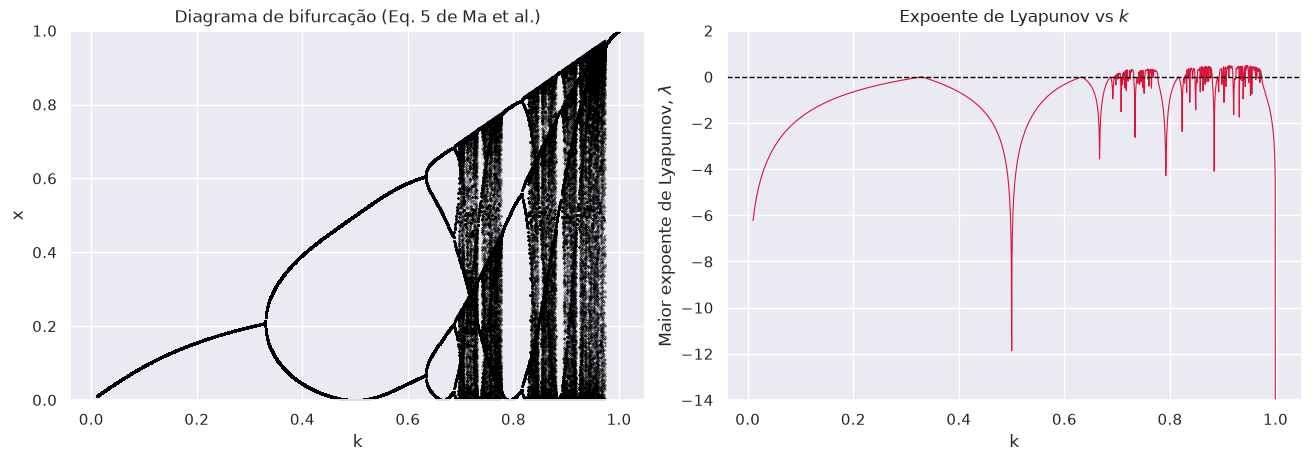

In [29]:
# Plotting

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axs[0].scatter(ks_sim, x_sim, s=0.05, color="black")
axs[0].set(xlabel="k", ylabel="x", title="Diagrama de bifurcação (Eq. 5 de Ma et al.)", ylim=(0, 1))

axs[1].plot(KS, lam_cos, color="crimson", lw=0.8)
axs[1].axhline(0, color="black", ls="--", lw=1)
axs[1].set(
    xlabel="k",
    ylabel=r"Maior expoente de Lyapunov, $\lambda$",
    title="Expoente de Lyapunov vs $k$",
    ylim=(-14, 2),
)


### 🔷 Interpretação
O comportamento do diagrama de bifurcação é semelhante ao que discutimos previamente, porém aqui podemos entender como os diferentes regimes dinâmicos se relacionam com o expoente de Lyapunov, permitindo caracterizar o comportamento caótico ou regular do sistema.

Inicialmente, observamos apenas um ramo no diagrama de bifurcação, o que corresponde a um expoente de Lyapunov negativo, sendo condizente com a presença de um ponto fixo atrator. No valor de $k$ em que ocorre a primeira duplicação de período, o expoente de Lyapunov atinge $\lambda=0$, indicando o limiar de perda de estabilidade do ponto fixo. Esse comportamento se repete nas próximas bifurcações por duplicação de período, de forma que o expoente de Lyapunov tende a zero nesses pontos.

Conforme aumentamos o parâmetro $k$, a dinâmica torna-se mais complexa, apresentando uma cascata de duplicações de período que conduz ao regime caótico. Nessa região, o expoente de Lyapunov passa a assumir valores positivos em diversos intervalos, indicando sensibilidade às condições iniciais e comportamento caótico.

Além disso, é possível identificar janelas de periodicidade em meio às regiões caóticas do diagrama de bifurcação, nas quais o expoente de Lyapunov volta a assumir valores negativos, indicando o retorno a um comportamento regular. Dessa forma, observa-se que o aumento do parâmetro de controle não implica necessariamente um aumento monotônico do caos.

